# 04 · Exploratory Data Analysis
**Milestone 3 — Kenyan Retail Customer & Sales Intelligence Capstone**

This notebook explores the cleaned data (`data/processed/sales_analytical.csv`, 2,988 lines) to answer
*who buys what, where and when*. It has five sections:

1. **Sales:** totals, monthly trend, year on year, weekly and daily patterns, calendar effects
2. **Products:** best and worst sellers, categories, profitability
3. **Customers:** spending, frequency, order value, high-value customers, behaviour
4. **Stores:** revenue, profit, counties, efficiency, growth
5. **Promotions:** discount levels, promotion periods, campaign performance

Every chart is followed by an **interpretation** (what the data shows) and a **business implication** (what management
should do about it). Summary tables come from `src/analysis/eda.py`.

> **Reading the numbers:** the data is a synthetic sample of about 3,000 loyalty-tracked lines, so absolute KES values are
> small. Focus on *patterns and comparisons*, not on totals. Customer-level analysis excludes the 21 walk-in lines
> that have no customer ID.

In [1]:
# --- Setup: make the project's "src" package importable from this notebook ---
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.visualization import style

style.apply_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from src.analysis import eda

sales = eda.load_analytical()
orders = eda.orders_table(sales)
print(f"{len(sales):,} lines | {len(orders):,} orders | {sales['transaction_date'].min().date()} to {sales['transaction_date'].max().date()}")

2,988 lines | 2,650 orders | 2024-01-01 to 2025-12-31


# 1. Sales performance
## 1.1 Headline KPIs

In [3]:
kpis = eda.kpi_summary(sales)
kpis.to_frame("value").style.format("{:,.2f}")

,value
Net revenue (KES),"2,179,214.72"
Gross profit (KES),"538,802.12"
Gross margin,0.25
Discounts given (KES),"43,142.28"
Orders,"2,650.00"
Units sold,"4,779.00"
Identified customers,"1,788.00"
Average order value (KES),822.35
Median order value (KES),450.00


**Interpretation:** over two years the sample produced **KES 2.18M in net revenue** and **KES 539K in gross profit**,
a **24.7% gross margin**. Discounts cost KES 43K, about 2% of revenue. The **average order is KES 822**, but the
**median is only KES 450**. A few large electronics and clothing baskets pull the average up.

**Business implication:** report the *median* basket alongside the average. "Average order value" alone overstates what
a typical shopper spends by about 80%.

## 1.2 Monthly revenue and profit trend

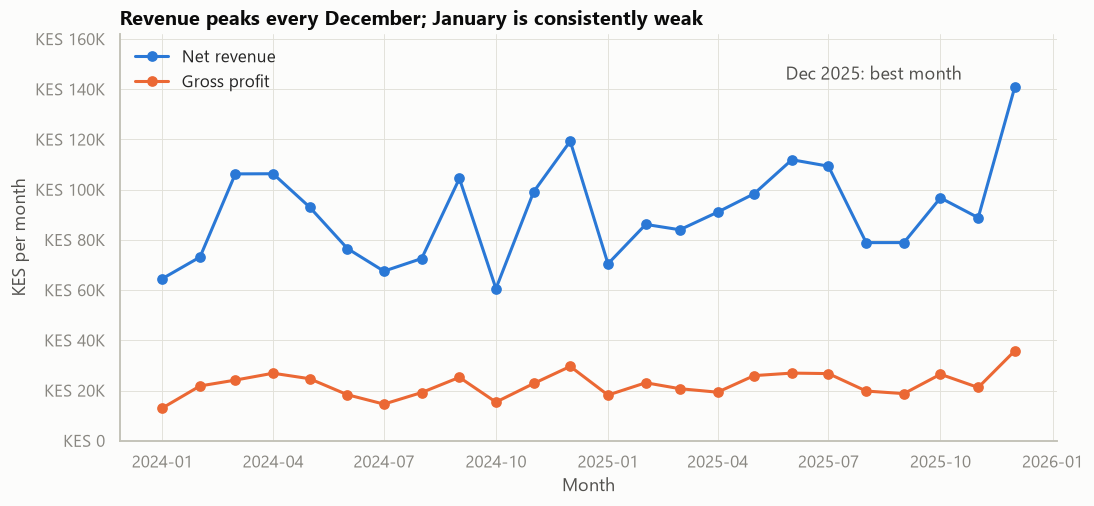

In [4]:
monthly = (sales.set_index("transaction_date")
           .resample("MS")[["total_amount", "profit"]].sum())

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(monthly.index, monthly["total_amount"], marker="o", color=style.SERIES[0], label="Net revenue")
ax.plot(monthly.index, monthly["profit"], marker="o", color=style.SERIES[1], label="Gross profit")
ax.annotate("Dec 2025: best month", (monthly.index[-1], monthly["total_amount"].iloc[-1]),
            xytext=(-150, 5), textcoords="offset points", color=style.INK["secondary"])
ax.yaxis.set_major_formatter(style.KES_FORMATTER)
ax.set_ylim(0, monthly["total_amount"].max() * 1.15)
ax.set_title("Revenue peaks every December; January is consistently weak")
ax.set_xlabel("Month")
ax.set_ylabel("KES per month")
ax.legend(loc="upper left")
style.save(fig, "m3_monthly_revenue_profit")
plt.show()

**Interpretation:** monthly revenue mostly ranges from KES 60K to 120K. **December is the high point** in both years
(KES 119K in 2024, KES 141K in 2025). **January is among the weakest months** (KES 65K and 70K). Profit follows revenue
closely, so no month is unusually unprofitable. Individual months are noisy because a single TV or smartphone
(KES 15–23K) can move a month's revenue by 10–20%.

**Business implication:** build stock and staff up from November for the December peak, and plan cash flow for a
January dip. Because single big-ticket sales swing monthly totals, judge performance on **quarterly or rolling
3-month** figures rather than single months.

## 1.3 Year-on-year performance

,revenue,profit,units,lines,orders,aov
year,,,,,,
2024,"1,043,614","255,757","2,447","1,467","1,300",803
2025,"1,135,601","283,046","2,332","1,521","1,350",841
Growth 2025 vs 2024,0.088,0.107,-0.047,0.037,0.038,0.048


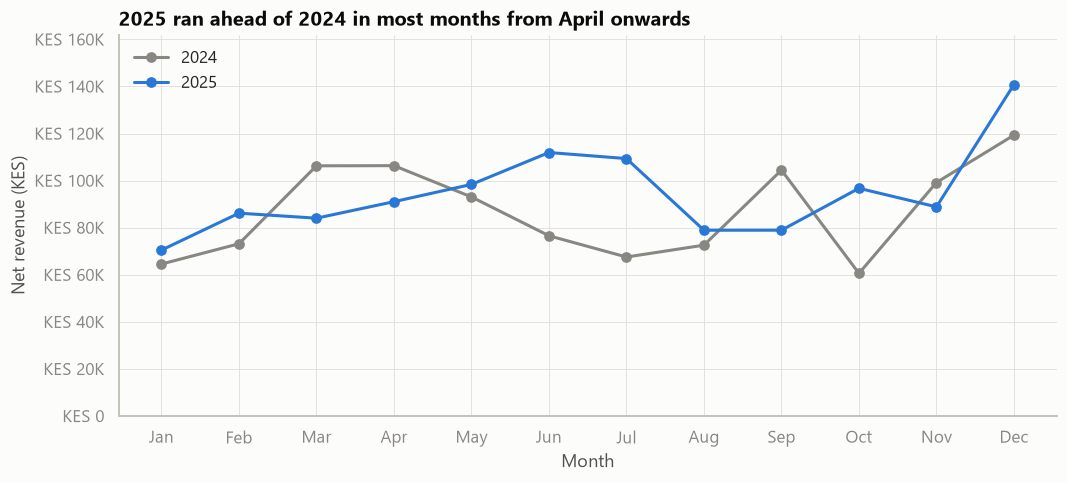

year,2024,2025,yoy_growth
quarter,,,
1,"243,994","240,668",-1.4%
2,"275,969","301,353",+9.2%
3,"244,554","267,196",+9.3%
4,"279,097","326,384",+16.9%


In [5]:
by_year = sales.groupby("year").agg(revenue=("total_amount", "sum"), profit=("profit", "sum"),
                                    units=("quantity", "sum"), lines=("transaction_id", "size"))
by_year = by_year.join(orders.groupby(orders["transaction_date"].dt.year).agg(orders=("order_id", "size"),
                                                                                aov=("order_value", "mean")))
growth = by_year.pct_change().iloc[[1]].rename(index={2025: "Growth 2025 vs 2024"})
display(pd.concat([by_year, growth]).style.format("{:,.3f}", subset=pd.IndexSlice["Growth 2025 vs 2024", :])
        .format("{:,.0f}", subset=pd.IndexSlice[[2024, 2025], :]))

month_year = sales.groupby(["year", "month"])["total_amount"].sum().unstack(0)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(month_year.index, month_year[2024], marker="o", color=style.NEUTRAL, label="2024")
ax.plot(month_year.index, month_year[2025], marker="o", color=style.SERIES[0], label="2025")
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.yaxis.set_major_formatter(style.KES_FORMATTER)
ax.set_ylim(0, month_year.max().max() * 1.15)
ax.set_title("2025 ran ahead of 2024 in most months from April onwards")
ax.set_xlabel("Month")
ax.set_ylabel("Net revenue (KES)")
ax.legend(loc="upper left")
style.save(fig, "m3_yoy_by_month")
plt.show()

quarterly = sales.groupby(["quarter", "year"])["total_amount"].sum().unstack()
quarterly["yoy_growth"] = quarterly[2025] / quarterly[2024] - 1
quarterly.style.format({2024: "{:,.0f}", 2025: "{:,.0f}", "yoy_growth": "{:+.1%}"})

**Interpretation:** revenue grew **8.8%** in 2025 and profit grew **10.7%**, but **units sold fell 4.7%**.
Orders rose 3.8% and the average order value rose 4.8%. In other words, growth came from **higher prices** (the January
2025 price review) and **larger baskets**, not from selling more items. By quarter, Q1 2025 was flat (−1.4%), then
growth accelerated through the year: Q2 +9.2%, Q3 +9.3%, **Q4 +16.9%**.

**Business implication:** growth driven by price is fragile. If competitors do not raise prices, volume could fall
further. Management should track **units and orders** alongside revenue, and treat the strong Q4 2025 as the base to
beat in Q4 2026.

## 1.4 Weekly and daily patterns

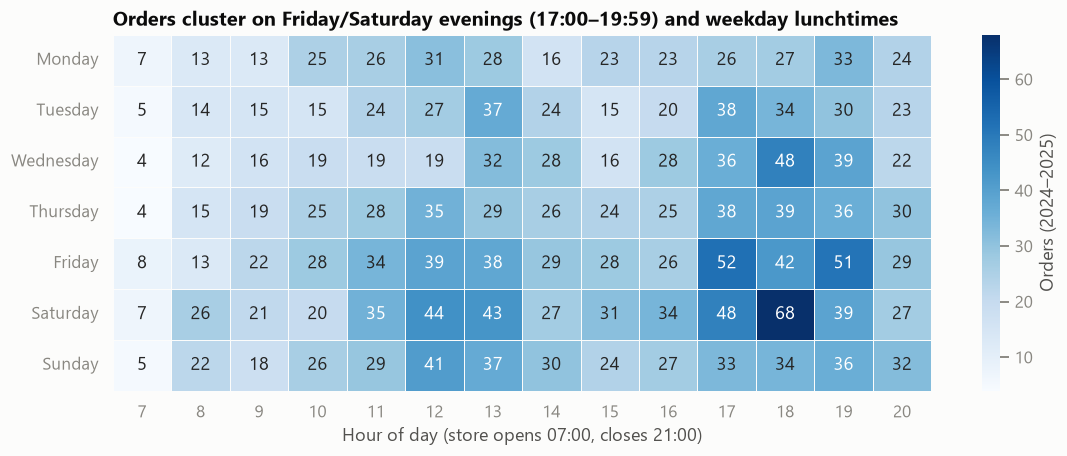

In [6]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
# One row per order (an order has one date and time), then count orders per weekday x hour
first_line = sales.drop_duplicates("order_id")
heat = (first_line.pivot_table(index="day_of_week", columns="hour", values="order_id",
                               aggfunc="count", fill_value=0)
        .reindex(weekday_order))

fig, ax = plt.subplots(figsize=(12, 4.2))
sns.heatmap(heat, cmap=style.SEQUENTIAL, annot=True, fmt="d", cbar_kws={"label": "Orders (2024–2025)"},
            linewidths=0.5, linecolor=style.INK["surface"], ax=ax)
ax.set_title("Orders cluster on Friday/Saturday evenings (17:00–19:59) and weekday lunchtimes")
ax.set_xlabel("Hour of day (store opens 07:00, closes 21:00)")
ax.set_ylabel("")
style.save(fig, "m3_weekday_hour_heatmap")
plt.show()

**Interpretation:** the busiest windows are **17:00–19:59**, especially on Fridays and Saturdays, with a second peak
at **12:00–13:59** (lunchtime). The first hour (07:00) and Monday/Tuesday mornings are the quietest.
Saturday (470 orders) and Friday (439) together carry a third of all orders. Monday (315) is the slowest day.

**Business implication:** schedule the most till staff from 17:00 to 20:00, and from Friday to Sunday. Use quiet
Monday and Tuesday mornings for deliveries, shelf resets and stock counts.

## 1.5 Seasonal and calendar effects: paydays, weekends and holidays

To compare fairly, we average **orders per calendar day**, including days with zero orders. Comparing raw order
counts would be misleading because there are far more ordinary days than holidays.

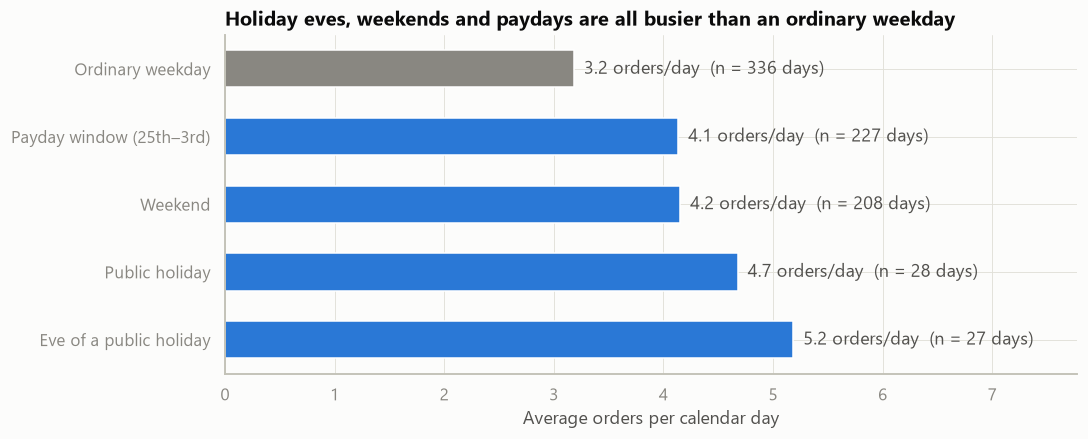

Revenue by calendar month (both years combined):
month
1     KES 135,018
2     KES 159,331
3     KES 190,313
4     KES 197,393
5     KES 191,436
6     KES 188,492
7     KES 176,887
8     KES 151,485
9     KES 183,378
10    KES 157,329
11    KES 188,028
12    KES 260,124


In [7]:
cal = eda.daily_orders_with_calendar(sales)
groups = {
    "Ordinary weekday": cal[~cal["is_weekend"] & ~cal["is_payday_window"] & ~cal["is_public_holiday"] & ~cal["is_holiday_eve"]],
    "Payday window (25th–3rd)": cal[cal["is_payday_window"]],
    "Weekend": cal[cal["is_weekend"]],
    "Public holiday": cal[cal["is_public_holiday"]],
    "Eve of a public holiday": cal[cal["is_holiday_eve"]],
}
effects = pd.DataFrame({"days": {k: len(v) for k, v in groups.items()},
                        "orders_per_day": {k: v["orders"].mean() for k, v in groups.items()}})

fig, ax = plt.subplots(figsize=(10, 4))
colors = [style.NEUTRAL] + [style.SERIES[0]] * 4
ax.barh(effects.index[::-1], effects["orders_per_day"][::-1], color=colors[::-1], height=0.55)
for y, (v, n) in enumerate(zip(effects["orders_per_day"][::-1], effects["days"][::-1])):
    ax.text(v, y, f"  {v:.1f} orders/day  (n = {n} days)", va="center", color=style.INK["secondary"])
ax.set_xlim(0, effects["orders_per_day"].max() * 1.5)
ax.set_title("Holiday eves, weekends and paydays are all busier than an ordinary weekday")
ax.set_xlabel("Average orders per calendar day")
style.save(fig, "m3_calendar_effects")
plt.show()

seasonal = cal.groupby("month")["revenue"].sum()
print("Revenue by calendar month (both years combined):")
print(seasonal.map("KES {:,.0f}".format).to_string())

**Interpretation:**
- An ordinary weekday averages about **3.2 orders**.
- The payday window and weekends each average about **4.1 orders a day**.
- Public holidays average **4.7**.
- The **eve of a public holiday** averages **5.2**, the highest of all.

By calendar month, December is clearly the strongest (KES 260K across the two Decembers) and January the weakest
(KES 135K). Holiday figures rest on only 27–28 days each, so they are indicative.

**Business implication:** the day before a holiday behaves like a mini-peak, as shoppers stock up. Kenya's holiday
calendar includes short-notice gazetted holidays (for example Idd-ul-Fitr and the October 2025 state funeral holiday),
so replenishment plans should be able to react within days. Month-end salary weeks are the natural time for price
promotions.

# 2. Product performance
## 2.1 Best- and least-selling products

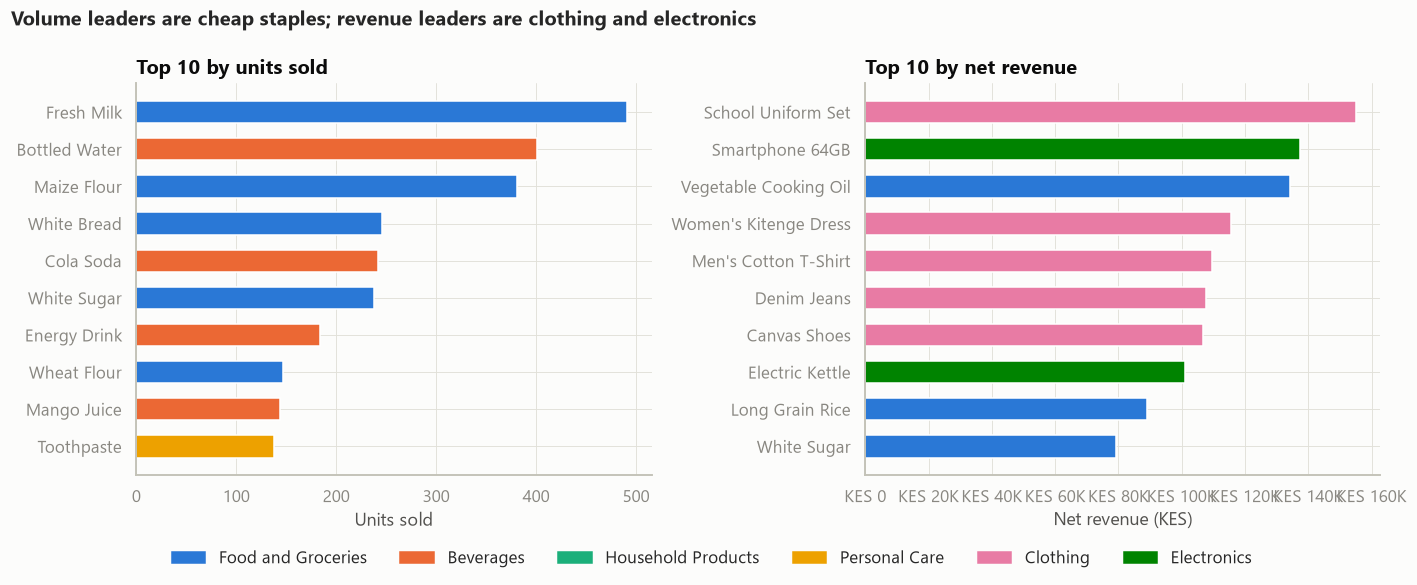

Least-selling products by units:


,product_name,category,units,revenue,margin
36,32-inch LED TV,Electronics,2,"45,758.00",0.16
35,Smartphone 64GB,Electronics,9,"137,391.00",0.16
23,Mop and Bucket Set,Household Products,14,"17,562.50",0.29
39,Solar Lantern,Electronics,20,"62,950.40",0.15
37,Bluetooth Earphones,Electronics,35,"62,971.20",0.24
38,Electric Kettle,Electronics,40,"100,900.00",0.21
29,Baby Diapers,Personal Care,46,"62,830.08",0.25
22,Insecticide Spray,Household Products,48,"24,752.55",0.24


In [8]:
products = eda.product_summary(sales)
top_units = products.nlargest(10, "units").sort_values("units")
top_rev = products.nlargest(10, "revenue").sort_values("revenue")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(top_units["product_name"], top_units["units"],
             color=[style.CATEGORY_COLORS[c] for c in top_units["category"]], height=0.6)
axes[0].set_title("Top 10 by units sold")
axes[0].set_xlabel("Units sold")
axes[1].barh(top_rev["product_name"], top_rev["revenue"],
             color=[style.CATEGORY_COLORS[c] for c in top_rev["category"]], height=0.6)
axes[1].xaxis.set_major_formatter(style.KES_FORMATTER)
axes[1].set_title("Top 10 by net revenue")
axes[1].set_xlabel("Net revenue (KES)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in style.CATEGORY_COLORS.values()]
fig.legend(handles, style.CATEGORY_COLORS.keys(), loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Volume leaders are cheap staples; revenue leaders are clothing and electronics",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
style.save(fig, "m3_top_products")
plt.show()

print("Least-selling products by units:")
products.nsmallest(8, "units")[["product_name", "category", "units", "revenue", "margin"]]

**Interpretation:**
- **Volume leaders** are everyday staples: fresh milk (491 units), bottled water (401) and maize flour (381).
- **Revenue leaders** are different: the **school uniform set** (KES 155K) is the single biggest earner, followed by
  the smartphone (KES 137K), cooking oil (KES 134K) and four clothing lines.
- **Least-selling** are big-ticket electronics: the 32-inch TV (2 units), the smartphone (9), the solar lantern (20).
  The mop and bucket set (14 units) is the only slow seller that isn't electronics.

**Business implication:** staples bring footfall and must never be out of stock, even though they earn little
revenue each. Few units of electronics are sold, so stock them **lean**, with fast reordering from suppliers, rather than holding inventory.
The mop and bucket set should be reviewed for range rationalization.

## 2.2 Revenue and profit by category

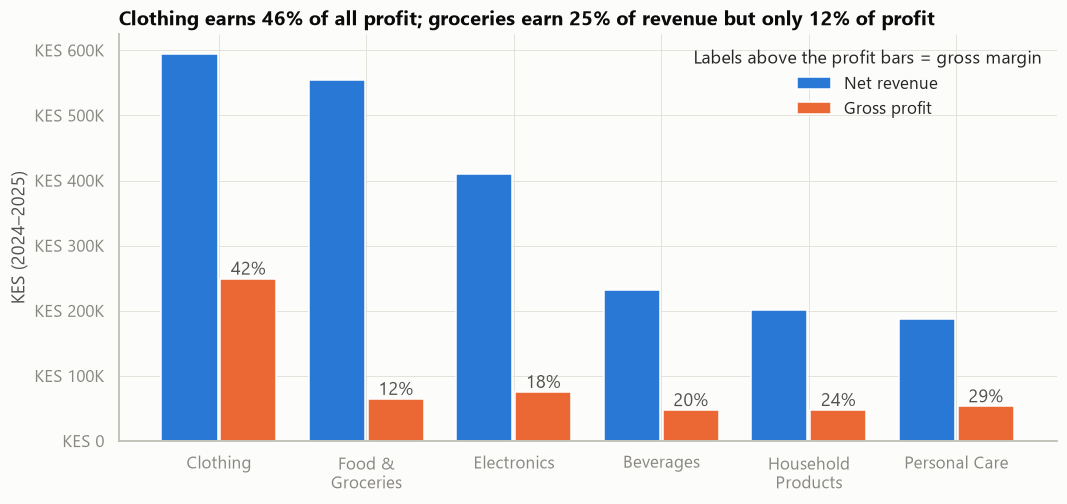

,revenue,profit,units,margin,revenue_share,profit_share
category,,,,,,
Clothing,"594,639","249,530",390,42.0%,27.3%,46.3%
Food and Groceries,"553,940","64,853","2,010",11.7%,25.4%,12.0%
Electronics,"409,971","75,493",106,18.4%,18.8%,14.0%
Beverages,"232,360","47,614","1,235",20.5%,10.7%,8.8%
Household Products,"200,929","47,826",579,23.8%,9.2%,8.9%
Personal Care,"187,376","53,486",459,28.5%,8.6%,9.9%


In [9]:
cat = (sales.groupby("category").agg(revenue=("total_amount", "sum"), profit=("profit", "sum"),
                                    units=("quantity", "sum"))
       .sort_values("revenue", ascending=False))
cat["margin"] = cat["profit"] / cat["revenue"]
cat["revenue_share"] = cat["revenue"] / cat["revenue"].sum()
cat["profit_share"] = cat["profit"] / cat["profit"].sum()

fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(cat))
ax.bar(x - 0.2, cat["revenue"], width=0.38, color=style.SERIES[0], label="Net revenue")
ax.bar(x + 0.2, cat["profit"], width=0.38, color=style.SERIES[1], label="Gross profit")
for xi, m in zip(x, cat["margin"]):
    ax.text(xi + 0.2, cat["profit"].iloc[xi], f"{m:.0%}", ha="center", va="bottom", color=style.INK["secondary"])
ax.set_xticks(x, cat.index.str.replace(" and ", " &\n").str.replace(" Products", "\nProducts"))
ax.yaxis.set_major_formatter(style.KES_FORMATTER)
ax.set_title("Clothing earns 46% of all profit; groceries earn 25% of revenue but only 12% of profit")
ax.set_ylabel("KES (2024–2025)")
ax.legend(title="Labels above the profit bars = gross margin")
style.save(fig, "m3_category_revenue_profit")
plt.show()
cat.style.format({"revenue": "{:,.0f}", "profit": "{:,.0f}", "units": "{:,.0f}",
                  "margin": "{:.1%}", "revenue_share": "{:.1%}", "profit_share": "{:.1%}"})

**Interpretation:** **Clothing** is the most important category. It earns 27% of revenue but **46% of gross profit**,
at a 42% margin. **Food and Groceries** is second on revenue (25%) but contributes only **12% of profit** (12% margin).
**Electronics** brings in 19% of revenue at an 18% margin. Personal care has a high margin (29%) but low volume.

**Business implication:** groceries drive traffic, while clothing drives profit. Floor space and promotional effort in
clothing, especially around back-to-school, offer the best profit return. Grocery pricing should stay competitive to
protect footfall rather than to make money directly.

## 2.3 Profitability by product

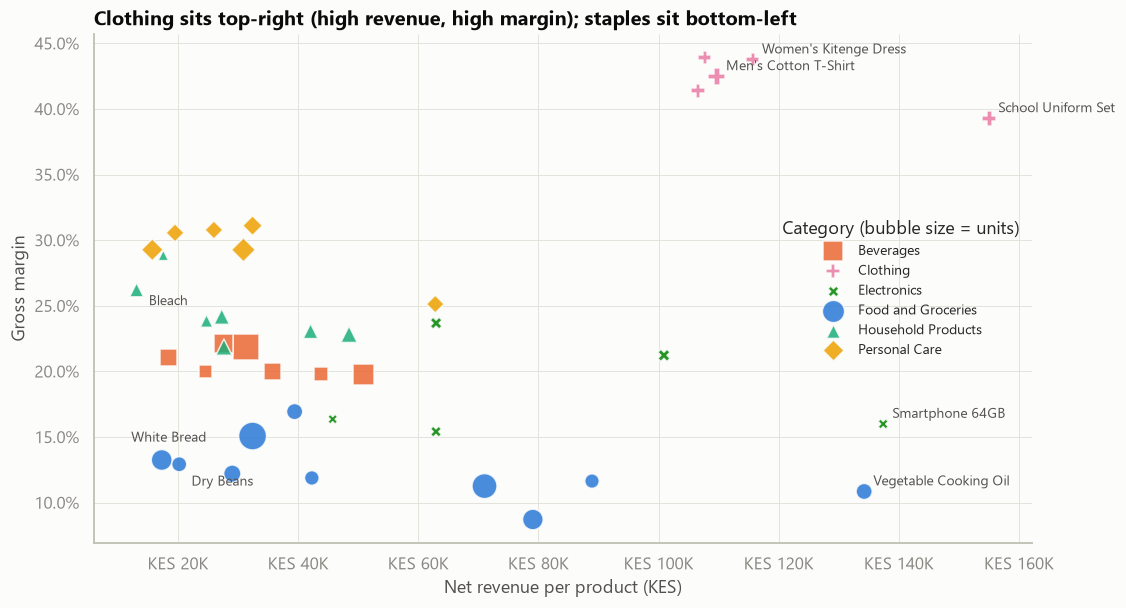

,product_name,category,revenue,profit,margin
32,School Uniform Set,Clothing,"155,023.20","60,901.20",0.39
31,Women's Kitenge Dress,Clothing,"115,675.20","50,623.20",0.44
33,Denim Jeans,Clothing,"107,681.20","47,297.20",0.44
30,Men's Cotton T-Shirt,Clothing,"109,702.70","46,609.90",0.42
34,Canvas Shoes,Clothing,"106,557.00","44,099.00",0.41


In [10]:
markers = dict(zip(style.CATEGORY_COLORS, ["o", "s", "^", "D", "P", "X"]))   # shape = second cue besides colour
fig, ax = plt.subplots(figsize=(11, 6))
for c, grp in products.groupby("category"):
    ax.scatter(grp["revenue"], grp["margin"], s=40 + grp["units"] * 0.6, color=style.CATEGORY_COLORS[c],
               marker=markers[c], alpha=0.85, edgecolor=style.INK["surface"], linewidth=1, label=c)
for _, r in products[products["revenue"].rank(ascending=False) <= 5].iterrows():
    ax.annotate(r["product_name"], (r["revenue"], r["margin"]), xytext=(6, 4), textcoords="offset points",
                fontsize=9, color=style.INK["secondary"])
# Lowest-profit products; offsets alternate so neighbouring labels do not overlap
for (_, r), offset in zip(products.nsmallest(3, "profit").iterrows(), [(-20, 12), (8, -14), (8, -10)]):
    ax.annotate(r["product_name"], (r["revenue"], r["margin"]), xytext=offset, textcoords="offset points",
                fontsize=9, color=style.INK["secondary"])
ax.xaxis.set_major_formatter(style.KES_FORMATTER)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Clothing sits top-right (high revenue, high margin); staples sit bottom-left")
ax.set_xlabel("Net revenue per product (KES)")
ax.set_ylabel("Gross margin")
ax.legend(title="Category (bubble size = units)", loc="center right", fontsize=9)
style.save(fig, "m3_product_profitability")
plt.show()
products.nlargest(5, "profit")[["product_name", "category", "revenue", "profit", "margin"]]

**Interpretation:** the five most profitable products are **all clothing**: the school uniform set (KES 61K profit),
kitenge dress, denim jeans, cotton T-shirt and canvas shoes, each at a 39–44% margin. The smartphone has high
revenue but only a 16% margin. The least profitable products are cheap staples, such as white bread (KES 2.3K profit
over two years), dry beans and bleach.

**Business implication:** never let the clothing range, particularly school uniforms, run short. Electronics should
be judged on profit per unit, not revenue. Low-profit staples are traffic builders and should be kept, but they
should not receive deep discounts (see section 5).

# 3. Customer behaviour
## 3.1 Customer spending distribution

count     1,788
mean      1,211
std       1,963
min          65
25%         312
50%         564
75%       1,445
90%       2,655
99%       7,727
max      27,887


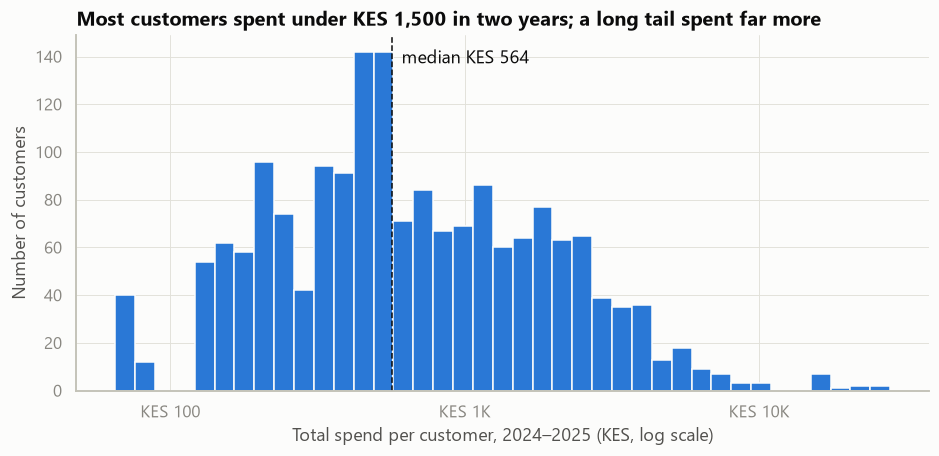

In [11]:
customers = eda.customer_summary(sales)
print(customers["spend"].describe(percentiles=[.25, .5, .75, .9, .99]).map("{:,.0f}".format).to_string())

fig, ax = plt.subplots(figsize=(10, 4.2))
bins = np.logspace(np.log10(customers["spend"].min()), np.log10(customers["spend"].max()), 40)
ax.hist(customers["spend"], bins=bins, color=style.HIGHLIGHT, edgecolor=style.INK["surface"])
ax.set_xscale("log")
ax.xaxis.set_major_formatter(style.KES_FORMATTER)
ax.axvline(customers["spend"].median(), color=style.INK["primary"], linestyle="--", linewidth=1)
ax.text(customers["spend"].median(), ax.get_ylim()[1] * 0.92, "  median KES 564", color=style.INK["primary"])
ax.set_title("Most customers spent under KES 1,500 in two years; a long tail spent far more")
ax.set_xlabel("Total spend per customer, 2024–2025 (KES, log scale)")
ax.set_ylabel("Number of customers")
style.save(fig, "m3_customer_spend_hist")
plt.show()

**Interpretation:** across 1,788 identified customers, the **median two-year spend is KES 564**, while the mean is
KES 1,211. The distribution is **strongly right-skewed**: 75% spent under KES 1,445, but the top 1% spent over
KES 7,700, and the largest customer spent KES 27,900. A log scale is needed to see the whole distribution.

**Business implication:** a "typical customer" is a low spender. Plans should target the tail separately, because a
few customers matter disproportionately. Skewed spending also means Milestone 5 must use tests that do not assume normality.

## 3.2 High-value customers: how concentrated is revenue?

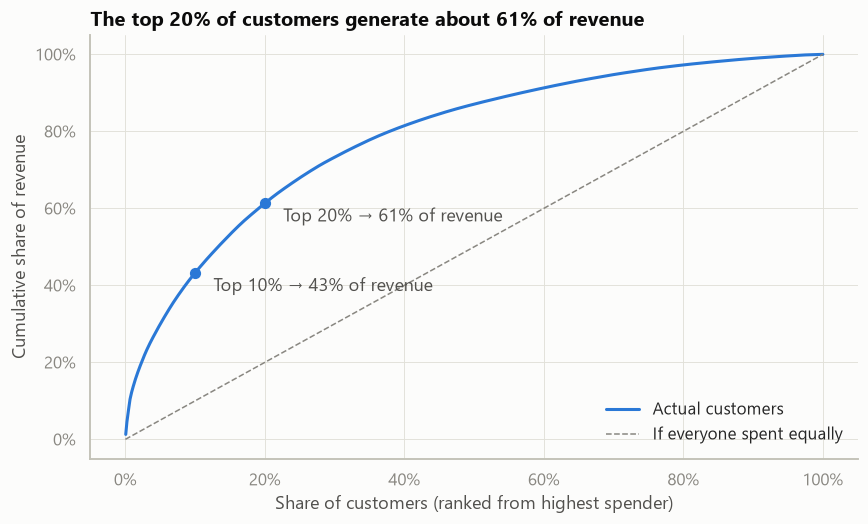

{'top 1%': '13.0%', 'top 5%': '30.0%', 'top 10%': '43.3%', 'top 20%': '61.4%', 'top 50%': '87.1%'}


,customer_id,orders,spend,avg_order_value,loyalty_member,recency_days
64,C0066,5,"27,887.00","5,577.40",Yes,0
1514,C1527,1,"24,044.00","24,044.00",No,209
44,C0046,9,"23,743.00","2,638.11",Yes,272
816,C0824,10,"22,423.00","2,242.30",No,35
908,C0916,5,"17,624.00","3,524.80",Yes,7
366,C0370,5,"16,515.00","3,303.00",Yes,380
705,C0713,2,"16,000.00","8,000.00",No,618
794,C0802,1,"15,949.00","15,949.00",No,61
320,C0324,1,"15,599.00","15,599.00",Yes,167
1395,C1406,1,"15,599.00","15,599.00",No,291


In [12]:
pareto = eda.cumulative_revenue_share(customers)
marks = {p: pareto.loc[(pareto["customer_share"] >= p).idxmax(), "revenue_share"] for p in [0.01, 0.05, 0.10, 0.20, 0.50]}

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(pareto["customer_share"], pareto["revenue_share"], color=style.SERIES[0], label="Actual customers")
ax.plot([0, 1], [0, 1], color=style.NEUTRAL, linestyle="--", linewidth=1, label="If everyone spent equally")
for p in [0.10, 0.20]:
    ax.scatter([p], [marks[p]], color=style.SERIES[0], s=40, zorder=3)
    ax.annotate(f"Top {p:.0%} → {marks[p]:.0%} of revenue", (p, marks[p]), xytext=(12, -12),
                textcoords="offset points", color=style.INK["secondary"])
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("The top 20% of customers generate about 61% of revenue")
ax.set_xlabel("Share of customers (ranked from highest spender)")
ax.set_ylabel("Cumulative share of revenue")
ax.legend(loc="lower right")
style.save(fig, "m3_customer_pareto")
plt.show()
print({f"top {k:.0%}": f"{v:.1%}" for k, v in marks.items()})
customers.nlargest(10, "spend")[["customer_id", "orders", "spend", "avg_order_value", "loyalty_member", "recency_days"]]

**Interpretation:** revenue is highly concentrated. The **top 1%** of customers generate 13% of revenue, the
**top 10%** generate 43%, and the **top 20%** generate 61%. This is close to the classic 80/20 pattern. The top-10
list mixes two types of customer: frequent loyal buyers (for example 9 or 10 orders) and **one-off big-ticket buyers**
(a single electronics purchase).

**Business implication:** the two types need different treatment. Frequent high spenders deserve retention
(loyalty rewards, personal offers). One-off big spenders are an opportunity for follow-up offers on accessories and
warranties. RFM segmentation in Milestone 4 will separate them formally.

## 3.3 Purchase frequency, order value and loyalty membership

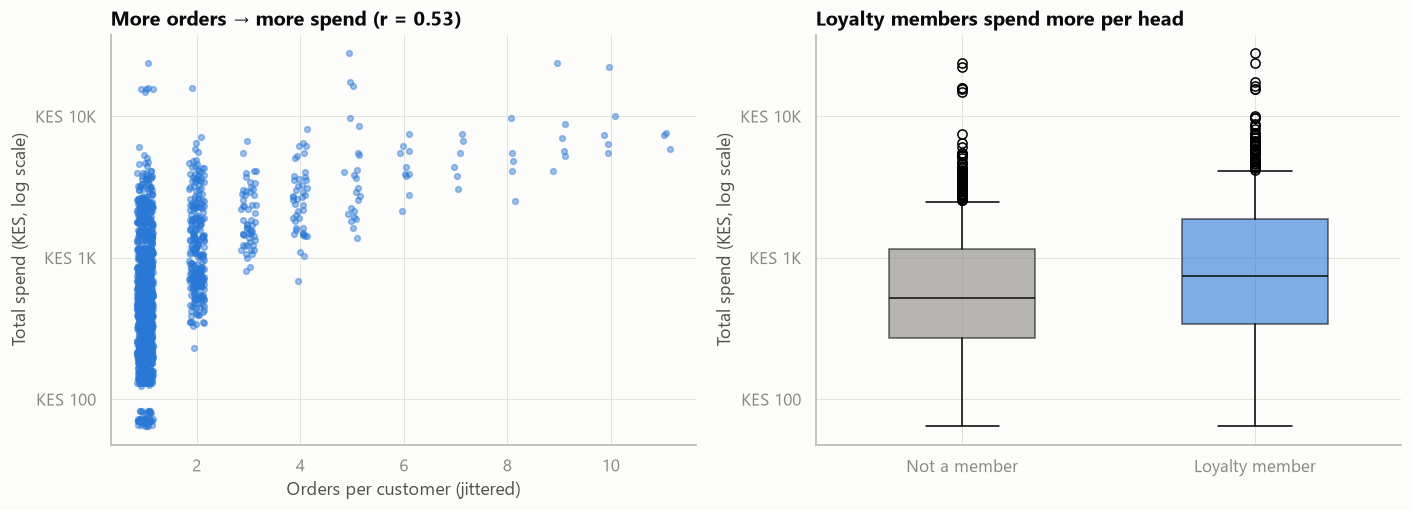

Correlation orders vs spend: 0.53
Repeat customers (2+ orders): 23.4% | their share of revenue: 47.7%


,customers,avg_orders,avg_spend,median_spend
loyalty_member,,,,
No,1208,1.20,"1,015.50",520.50
Yes,580,2.00,"1,617.10",746.30


,customers,avg_spend,median_spend
age_band,,,
18-24,315,"1,298.00",695.00
25-34,612,"1,155.00",541.00
35-44,470,"1,253.00",559.00
45-54,246,"1,110.00",525.00
55+,145,"1,290.00",666.00


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Frequency vs spend (scatter)
axes[0].scatter(customers["orders"] + np.random.default_rng(0).uniform(-0.15, 0.15, len(customers)),
                customers["spend"], s=14, alpha=0.45, color=style.HIGHLIGHT)
axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(style.KES_FORMATTER)
axes[0].set_title("More orders → more spend (r = 0.53)")
axes[0].set_xlabel("Orders per customer (jittered)")
axes[0].set_ylabel("Total spend (KES, log scale)")

# Spend by loyalty membership (boxplot)
data = [customers.loc[customers["loyalty_member"] == g, "spend"] for g in ["No", "Yes"]]
bp = axes[1].boxplot(data, tick_labels=["Not a member", "Loyalty member"], patch_artist=True, widths=0.5,
                     medianprops={"color": style.INK["primary"]})
for patch, colour in zip(bp["boxes"], [style.NEUTRAL, style.SERIES[0]]):
    patch.set_facecolor(colour)
    patch.set_alpha(0.6)
axes[1].set_yscale("log")
axes[1].yaxis.set_major_formatter(style.KES_FORMATTER)
axes[1].set_title("Loyalty members spend more per head")
axes[1].set_ylabel("Total spend (KES, log scale)")
fig.tight_layout()
style.save(fig, "m3_frequency_loyalty")
plt.show()

print("Correlation orders vs spend:", round(customers[["orders", "spend"]].corr().iloc[0, 1], 2))
print("Repeat customers (2+ orders):", f"{(customers['orders'] >= 2).mean():.1%}",
      "| their share of revenue:", f"{customers.loc[customers['orders'] >= 2, 'spend'].sum() / customers['spend'].sum():.1%}")
display(customers.groupby("loyalty_member").agg(customers=("customer_id", "size"), avg_orders=("orders", "mean"),
                                                avg_spend=("spend", "mean"), median_spend=("spend", "median")).round(1))
display(customers.groupby("age_band").agg(customers=("customer_id", "size"), avg_spend=("spend", "mean"),
                                          median_spend=("spend", "median")).round(0))

**Interpretation:**
- **Frequency drives value.** Orders and spend are moderately correlated (r = 0.53). Only **23% of customers bought
  more than once**, yet these repeat customers produce **48% of revenue**.
- **Loyalty members** average 2.0 orders and KES 1,617, compared with 1.2 orders and KES 1,016 for non-members.
  Note that this is an *association*: loyal shoppers may simply be more likely to join.
- **Demographics barely matter.** Average spend is similar across age bands (KES 1,110–1,298) and genders.

**Business implication:** turning one-off buyers into second-time buyers is the biggest lever. 77% of customers never
returned. A "second visit" offer (for example a voucher on the first receipt) and loyalty sign-up at the till are worth
testing. Targeting by age or gender would not help, because behaviour is what separates customers.

## 3.4 Customer purchasing behaviour: are repeat customers still active?

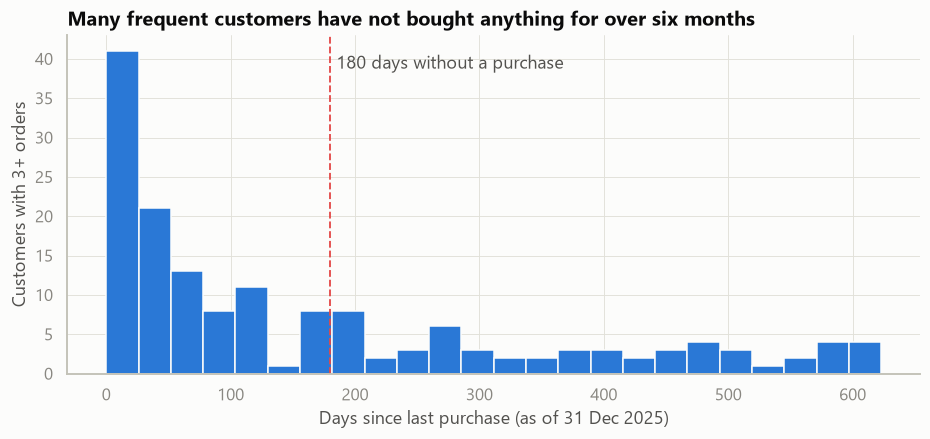

Customers with 3+ orders: 158; inactive > 180 days: 55 (35%); their past spend: KES 230,177


In [14]:
repeaters = customers[customers["orders"] >= 3]
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(repeaters["recency_days"], bins=24, color=style.HIGHLIGHT, edgecolor=style.INK["surface"])
ax.axvline(180, color=style.SERIES[7], linestyle="--", linewidth=1.2)
ax.text(185, ax.get_ylim()[1] * 0.9, "180 days without a purchase", color=style.INK["secondary"])
ax.set_title("Many frequent customers have not bought anything for over six months")
ax.set_xlabel("Days since last purchase (as of 31 Dec 2025)")
ax.set_ylabel("Customers with 3+ orders")
style.save(fig, "m3_repeater_recency")
plt.show()
print(f"Customers with 3+ orders: {len(repeaters)}; inactive > 180 days: {(repeaters['recency_days'] > 180).sum()} "
      f"({(repeaters['recency_days'] > 180).mean():.0%}); their past spend: KES {repeaters.loc[repeaters['recency_days'] > 180, 'spend'].sum():,.0f}")

**Interpretation:** of 158 customers who placed three or more orders, **55 (35%) have not purchased for more than
180 days**. Together they had spent KES 230K. These were valuable, engaged shoppers, and their silence is a warning sign that they may be
**drifting away**, possibly to a competitor.

**Business implication:** this group is the target list for a win-back campaign. Milestone 6 will define a defensible
inactivity threshold and build the formal at-risk customer list. The 180-day line here is only an exploratory marker.

# 4. Store performance
## 4.1 Revenue and profit by store

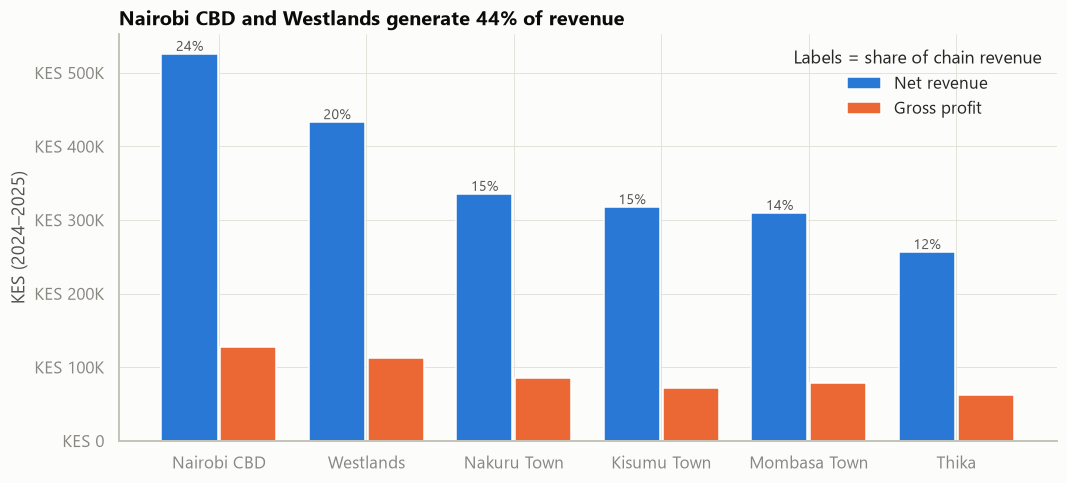

,town,revenue,profit,units,customers,orders,avg_order_value,county,store_format,floor_area_sqm,margin,revenue_share,revenue_per_sqm
0,Nairobi CBD,"525,975","127,986","1,152",473,643,818,Nairobi,Flagship,2400,24.3%,24.1%,219
1,Westlands,"433,184","112,527",857,363,482,899,Nairobi,Flagship,2100,26.0%,19.9%,206
2,Nakuru Town,"335,755","85,657",739,270,371,905,Nakuru,Standard,1400,25.5%,15.4%,240
3,Kisumu Town,"317,705","71,513",629,264,356,892,Kisumu,Standard,1300,22.5%,14.6%,244
4,Mombasa Town,"309,860","78,976",800,313,458,677,Mombasa,Standard,1600,25.5%,14.2%,194
5,Thika,"256,735","62,143",602,242,340,755,Kiambu,Compact,900,24.2%,11.8%,285


In [15]:
stores = eda.store_summary(sales)
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(stores))
ax.bar(x - 0.2, stores["revenue"], width=0.38, color=style.SERIES[0], label="Net revenue")
ax.bar(x + 0.2, stores["profit"], width=0.38, color=style.SERIES[1], label="Gross profit")
for xi, (rev, share, m) in enumerate(zip(stores["revenue"], stores["revenue_share"], stores["margin"])):
    ax.text(xi - 0.2, rev, f"{share:.0%}", ha="center", va="bottom", color=style.INK["secondary"], fontsize=9)
ax.set_xticks(x, stores["town"])
ax.yaxis.set_major_formatter(style.KES_FORMATTER)
ax.set_title("Nairobi CBD and Westlands generate 44% of revenue")
ax.set_ylabel("KES (2024–2025)")
ax.legend(title="Labels = share of chain revenue")
style.save(fig, "m3_store_revenue_profit")
plt.show()
stores.style.format({"revenue": "{:,.0f}", "profit": "{:,.0f}", "units": "{:,.0f}", "avg_order_value": "{:,.0f}",
                     "margin": "{:.1%}", "revenue_share": "{:.1%}", "revenue_per_sqm": "{:,.0f}"})

**Interpretation:** the store ranking is **Nairobi CBD** (24% of revenue), **Westlands** (20%), then Nakuru, Kisumu,
Mombasa and Thika (12–15% each). **Westlands has the highest margin (26.0%)**, helped by its larger, clothing-heavy
baskets. **Kisumu has the lowest margin (22.5%)** because almost a quarter (23%) of its revenue comes from low-margin electronics.
**Mombasa** has many orders (458, third highest) but the **lowest average order value (KES 677)**. It sells many
small, beverage-led baskets.

**Business implication:** Mombasa's problem is basket size, not footfall. Bundles and "add-on" displays at the till
could lift its order value. Kisumu's margin would benefit from more clothing and personal care.

## 4.2 County comparison and space efficiency

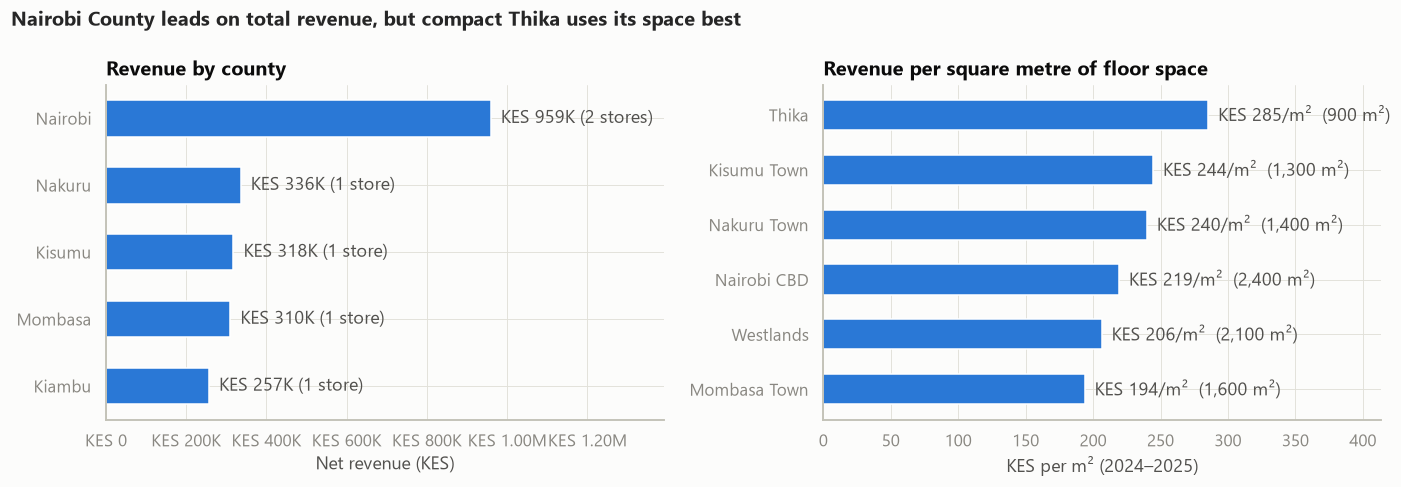

,revenue,profit,stores,revenue_per_store
county,,,,
Nairobi,"959,159","240,513",2,"479,579"
Nakuru,"335,755","85,657",1,"335,755"
Kisumu,"317,705","71,513",1,"317,705"
Mombasa,"309,860","78,976",1,"309,860"
Kiambu,"256,735","62,143",1,"256,735"


In [16]:
county = sales.groupby("county").agg(revenue=("total_amount", "sum"), profit=("profit", "sum"),
                                     stores=("store_id", "nunique")).sort_values("revenue", ascending=False)
county["revenue_per_store"] = county["revenue"] / county["stores"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(county.index[::-1], county["revenue"][::-1], color=style.HIGHLIGHT, height=0.55)
for y, (v, n) in enumerate(zip(county["revenue"][::-1], county["stores"][::-1])):
    axes[0].text(v, y, f"  {style.kes(v)} ({n} store{'s' if n > 1 else ''})", va="center", color=style.INK["secondary"])
axes[0].set_xlim(0, county["revenue"].max() * 1.45)
axes[0].xaxis.set_major_formatter(style.KES_FORMATTER)
axes[0].set_title("Revenue by county")
axes[0].set_xlabel("Net revenue (KES)")

eff = stores.sort_values("revenue_per_sqm")
axes[1].barh(eff["town"], eff["revenue_per_sqm"], color=style.HIGHLIGHT, height=0.55)
for y, (v, a) in enumerate(zip(eff["revenue_per_sqm"], eff["floor_area_sqm"])):
    axes[1].text(v, y, f"  KES {v:,.0f}/m²  ({a:,} m²)", va="center", color=style.INK["secondary"])
axes[1].set_xlim(0, eff["revenue_per_sqm"].max() * 1.45)
axes[1].set_title("Revenue per square metre of floor space")
axes[1].set_xlabel("KES per m² (2024–2025)")
fig.suptitle("Nairobi County leads on total revenue, but compact Thika uses its space best",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
style.save(fig, "m3_county_efficiency")
plt.show()
county.style.format({"revenue": "{:,.0f}", "profit": "{:,.0f}", "revenue_per_store": "{:,.0f}"})

**Interpretation:** **Nairobi County** (two stores) brings in KES 959K, 44% of the chain. Per store, though, Nairobi's
average (KES 480K) is not far above Nakuru's single store (KES 336K). On **space efficiency** the ranking flips.
**Thika**, the smallest store (900 m²), earns the **most revenue per square metre (KES 285/m²)**. **Mombasa**
(KES 194/m²) and **Westlands** (KES 206/m²) earn the least from their space.

**Business implication:** the compact format looks efficient and could be a low-cost model for expansion into new
towns. Mombasa's large floor is under-used, which points to a range or layout review.

## 4.3 Store category mix and growth

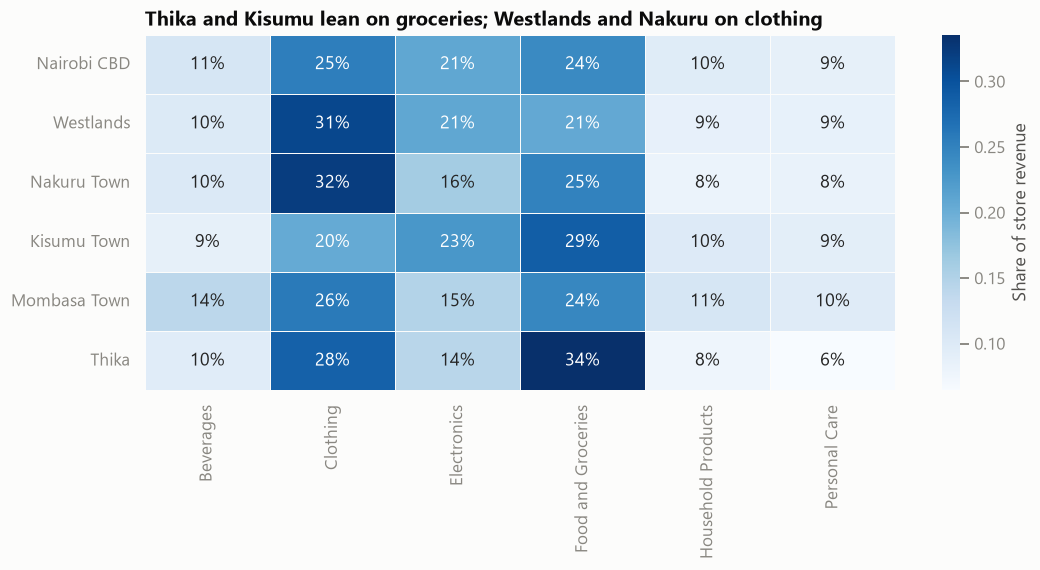

In [17]:
mix = pd.crosstab(sales["town"], sales["category"], values=sales["total_amount"], aggfunc="sum", normalize="index")
mix = mix.loc[stores["town"]]

fig, ax = plt.subplots(figsize=(11, 4.2))
sns.heatmap(mix, cmap=style.SEQUENTIAL, annot=True, fmt=".0%", cbar_kws={"label": "Share of store revenue"},
            linewidths=0.5, linecolor=style.INK["surface"], ax=ax)
ax.set_title("Thika and Kisumu lean on groceries; Westlands and Nakuru on clothing")
ax.set_xlabel("")
ax.set_ylabel("")
style.save(fig, "m3_store_category_mix")
plt.show()

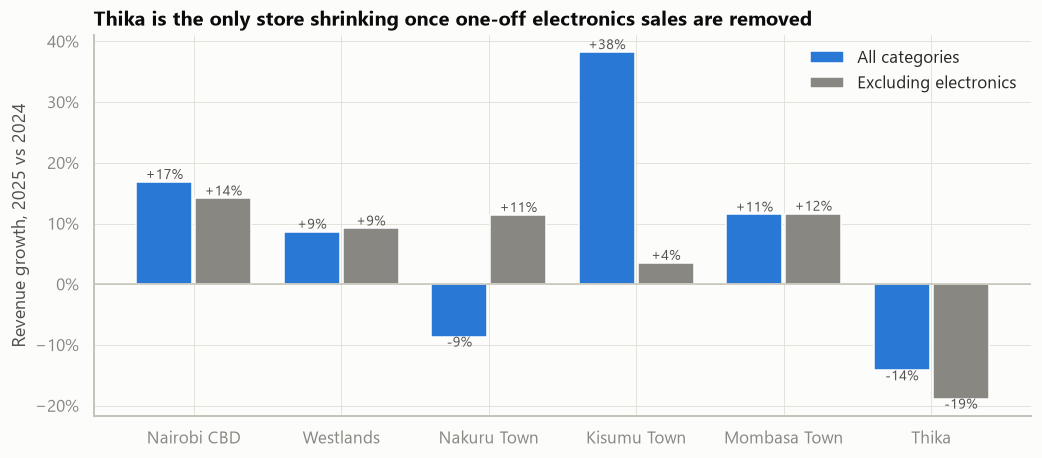

,all_categories,excluding_electronics
town,,
Nairobi CBD,+16.9%,+14.1%
Westlands,+8.7%,+9.2%
Nakuru Town,-8.6%,+11.4%
Kisumu Town,+38.2%,+3.5%
Mombasa Town,+11.5%,+11.6%
Thika,-14.2%,-18.8%


In [18]:
by_store_year = sales.groupby(["town", "year"])["total_amount"].sum().unstack()
no_elec = sales[sales["category"] != "Electronics"].groupby(["town", "year"])["total_amount"].sum().unstack()
growth = pd.DataFrame({"all_categories": by_store_year[2025] / by_store_year[2024] - 1,
                       "excluding_electronics": no_elec[2025] / no_elec[2024] - 1}).loc[stores["town"]]

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(growth))
ax.bar(x - 0.2, growth["all_categories"], width=0.38, color=style.SERIES[0], label="All categories")
ax.bar(x + 0.2, growth["excluding_electronics"], width=0.38, color=style.NEUTRAL, label="Excluding electronics")
ax.axhline(0, color=style.INK["axis"], linewidth=1)
for xi, (a, b) in enumerate(zip(growth["all_categories"], growth["excluding_electronics"])):
    ax.text(xi - 0.2, a, f"{a:+.0%}", ha="center", va="bottom" if a >= 0 else "top", fontsize=9, color=style.INK["secondary"])
    ax.text(xi + 0.2, b, f"{b:+.0%}", ha="center", va="bottom" if b >= 0 else "top", fontsize=9, color=style.INK["secondary"])
ax.set_xticks(x, growth.index)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Thika is the only store shrinking once one-off electronics sales are removed")
ax.set_ylabel("Revenue growth, 2025 vs 2024")
ax.legend(loc="upper right")
style.save(fig, "m3_store_growth")
plt.show()
growth.style.format("{:+.1%}")

**Interpretation:** the headline growth figures are distorted by a handful of electronics sales.
- **Kisumu** appears to grow +38%, but most of that came from electronics: its electronics revenue jumped from KES 13K
  to 60K. Excluding electronics, it grew only **+3.5%**.
- **Nakuru** appears to shrink (−9%), yet it grew **+11%** excluding electronics.
- **Thika** is the only store that declines on both measures (**−14% overall, −19% excluding electronics**).

**Business implication:** Thika needs attention. It is the most space-efficient store, but its core grocery and
household sales are falling, which could mean local competition or customers drifting away. More generally, store
targets should be set on **revenue excluding big-ticket electronics**, so that one TV sale does not mask a real trend.

# 5. Promotions
## 5.1 Discount distribution

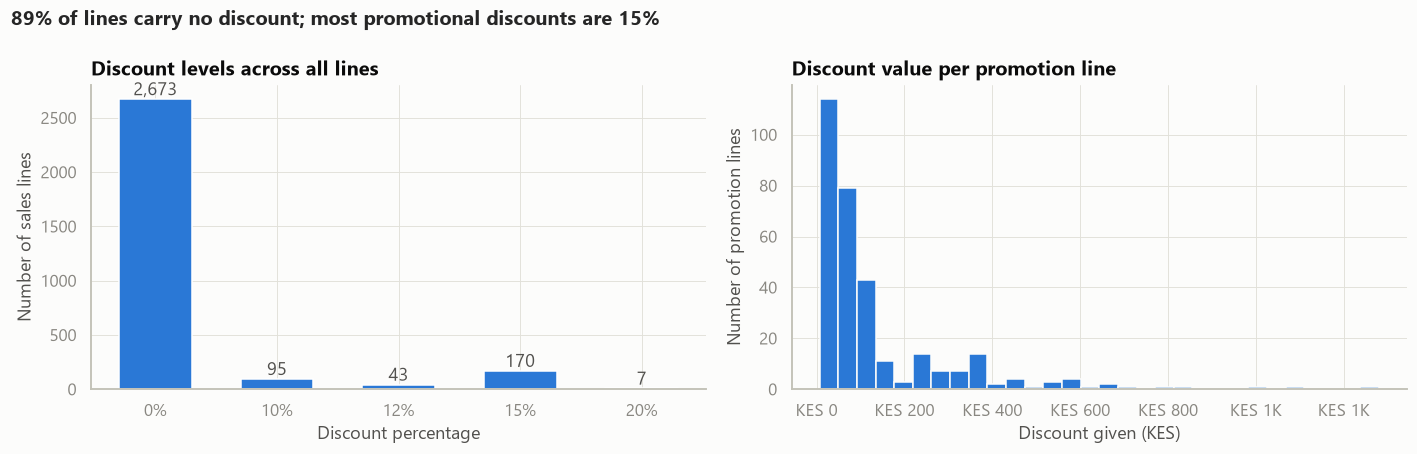

Promotion lines: 315 (10.5%); total discount KES 43,142; median discount per promo line KES 69


In [19]:
disc = sales["discount_percentage"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(disc.index.astype(int).astype(str) + "%", disc.values, color=style.HIGHLIGHT, width=0.6)
for xi, v in enumerate(disc.values):
    axes[0].text(xi, v, f"{v:,}", ha="center", va="bottom", color=style.INK["secondary"])
axes[0].set_title("Discount levels across all lines")
axes[0].set_xlabel("Discount percentage")
axes[0].set_ylabel("Number of sales lines")

promo_lines = sales[sales["is_promo"]]
axes[1].hist(promo_lines["discount_amount"], bins=30, color=style.HIGHLIGHT, edgecolor=style.INK["surface"])
axes[1].xaxis.set_major_formatter(style.KES_FORMATTER)
axes[1].set_title("Discount value per promotion line")
axes[1].set_xlabel("Discount given (KES)")
axes[1].set_ylabel("Number of promotion lines")
fig.suptitle("89% of lines carry no discount; most promotional discounts are 15%",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
style.save(fig, "m3_discount_distribution")
plt.show()
print(f"Promotion lines: {len(promo_lines)} ({len(promo_lines)/len(sales):.1%}); total discount KES {sales['discount_amount'].sum():,.0f}; "
      f"median discount per promo line KES {promo_lines['discount_amount'].median():,.0f}")

**Interpretation:** 2,673 lines (89.5%) were sold at full price. Of the 315 promotion lines, most carry a **15%**
discount (170 lines), followed by 10% (95) and 12% (43). Only 7 lines received the 20% Black Friday electronics
discount. The discount value per line is small (typically tens of shillings) with a long tail, the largest
being KES 1,280 off electronics.

**Business implication:** promotions are a small, targeted tool rather than a constant price war, which protects
margins. The deepest discounts fall on the lowest-margin category (electronics), which is checked below.

## 5.2 Sales during promotional periods: do promotion lines behave differently?

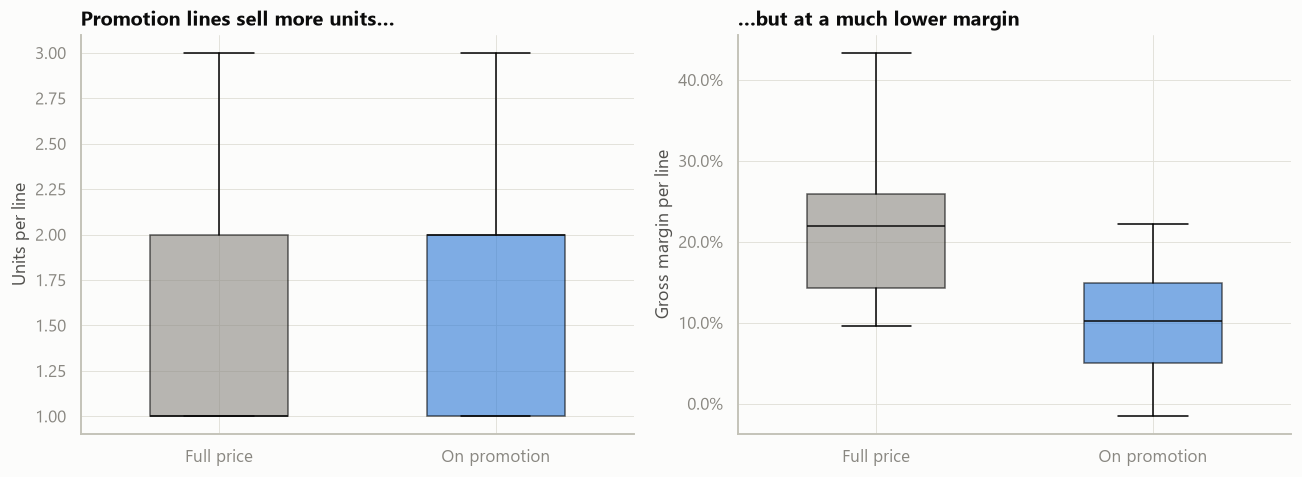

,lines,mean_units,mean_line_revenue,mean_margin
is_promo,,,,
False,2673,1.55,717.40,0.22
True,315,2.04,830.46,0.13


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, label in [(axes[0], "quantity", "Units per line"), (axes[1], "profit_margin", "Gross margin per line")]:
    data = [sales.loc[~sales["is_promo"], col], sales.loc[sales["is_promo"], col]]
    bp = ax.boxplot(data, tick_labels=["Full price", "On promotion"], patch_artist=True, widths=0.5,
                    showfliers=False, medianprops={"color": style.INK["primary"]})
    for patch, colour in zip(bp["boxes"], [style.NEUTRAL, style.SERIES[0]]):
        patch.set_facecolor(colour)
        patch.set_alpha(0.6)
    ax.set_ylabel(label)
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set_title("Promotion lines sell more units…")
axes[1].set_title("…but at a much lower margin")
fig.tight_layout()
style.save(fig, "m3_promo_vs_full_price")
plt.show()
sales.groupby("is_promo").agg(lines=("transaction_id", "size"), mean_units=("quantity", "mean"),
                              mean_line_revenue=("total_amount", "mean"), mean_margin=("profit_margin", "mean")).round(3)

**Interpretation:** promotion lines average **2.04 units**, against 1.55 at full price (+32%), and slightly higher
revenue per line (KES 830 against KES 717). However, their average margin is **13.3% against 22.4%**.
The boxplots hide outliers to keep the comparison readable.

**Business implication:** promotions do move volume, but every promoted unit earns less. A campaign is only
worthwhile if the extra units more than make up for the lost margin. This is assessed per campaign below and tested
statistically in Milestone 5.

## 5.3 Campaign performance

For each campaign we compare **target-category units per day during the campaign** with a **baseline**: the same
category on non-promotion days within 28 days before and after it. Days outside the study period are excluded, so
January 2024 campaigns still have a baseline.

> ⚠️ This is a descriptive comparison, **not proof of causation**. Several campaigns run during seasonal peaks
> (back-to-school, Easter, December), so part of each "lift" is seasonal demand.

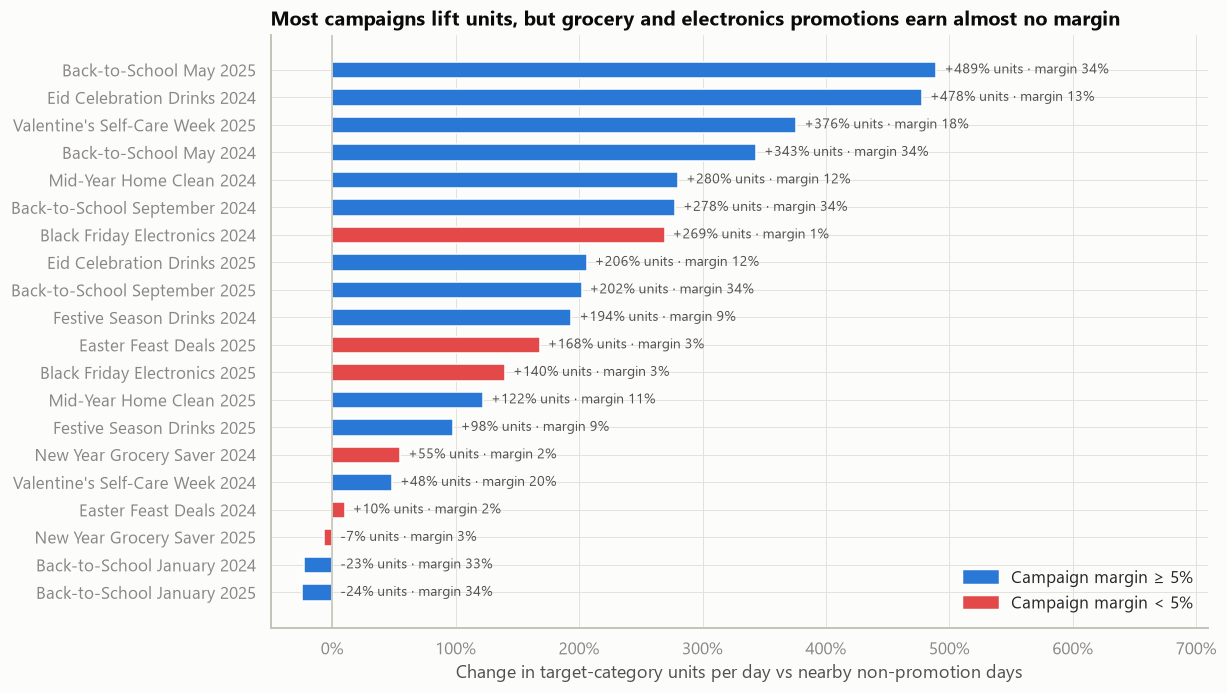

,promotion_id,promotion_name,year,discount_pct,units_per_day_promo,units_per_day_baseline,unit_lift,promo_revenue,discount_cost,promo_profit,promo_margin
0,PR01,New Year Grocery Saver,2024,10.000000,3.15,2.03,+55%,"8,752",972,190,2%
1,PR02,Back-to-School January,2024,15.000000,0.40,0.52,-23%,"9,860","1,740","3,220",33%
2,PR03,Valentine's Self-Care Week,2024,12.000000,0.88,0.59,+48%,924,126,189,20%
3,PR04,Easter Feast Deals,2024,10.000000,3.91,3.55,+10%,"12,609","1,401",307,2%
4,PR05,Eid Celebration Drinks,2024,12.000000,9.70,1.68,+478%,"10,930","1,490","1,413",13%
5,PR06,Back-to-School May,2024,15.000000,2.45,0.55,+343%,"32,130","5,670","10,990",34%
6,PR07,Mid-Year Home Clean,2024,15.000000,1.83,0.48,+280%,"9,673","1,707","1,193",12%
7,PR08,Back-to-School September,2024,15.000000,1.42,0.38,+278%,"22,568","3,982","7,728",34%
8,PR09,Black Friday Electronics,2024,20.000000,0.86,0.23,+269%,"13,120","3,280",70,1%
9,PR10,Festive Season Drinks,2024,15.000000,3.88,1.32,+194%,"10,438","1,842",947,9%


In [21]:
promo = eda.promotion_performance(sales)
show = promo.sort_values("unit_lift")
labels = show["promotion_name"] + " " + show["year"].astype(str)
colors = [style.SERIES[7] if m < 0.05 else style.SERIES[0] for m in show["promo_margin"]]

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(labels, show["unit_lift"], color=colors, height=0.6)
ax.axvline(0, color=style.INK["axis"], linewidth=1)
for y, (lift, m) in enumerate(zip(show["unit_lift"], show["promo_margin"])):
    ax.text(lift if lift > 0 else 0, y, f"  {lift:+.0%} units · margin {m:.0%}", va="center", fontsize=9,
            color=style.INK["secondary"])
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(min(show["unit_lift"].min() * 1.2, -0.5), show["unit_lift"].max() * 1.45)
ax.set_title("Most campaigns lift units, but grocery and electronics promotions earn almost no margin")
ax.set_xlabel("Change in target-category units per day vs nearby non-promotion days")
handles = [plt.Rectangle((0, 0), 1, 1, color=style.SERIES[0]), plt.Rectangle((0, 0), 1, 1, color=style.SERIES[7])]
ax.legend(handles, ["Campaign margin ≥ 5%", "Campaign margin < 5%"], loc="lower right")
style.save(fig, "m3_promotion_lift")
plt.show()

promo[["promotion_id", "promotion_name", "year", "discount_pct", "units_per_day_promo", "units_per_day_baseline",
       "unit_lift", "promo_revenue", "discount_cost", "promo_profit", "promo_margin"]].style.format({
    "units_per_day_promo": "{:.2f}", "units_per_day_baseline": "{:.2f}", "unit_lift": "{:+.0%}",
    "promo_revenue": "{:,.0f}", "discount_cost": "{:,.0f}", "promo_profit": "{:,.0f}", "promo_margin": "{:.0%}"})

In [22]:
by_cat = promo.groupby("target_category").agg(campaigns=("promotion_id", "size"),
                                              discount_pct=("discount_pct", "first"),
                                              revenue=("promo_revenue", "sum"), discount_cost=("discount_cost", "sum"),
                                              profit=("promo_profit", "sum"))
by_cat["campaign_margin"] = by_cat["profit"] / by_cat["revenue"]
by_cat["normal_category_margin"] = sales[~sales["is_promo"]].groupby("category").apply(
    lambda d: d["profit"].sum() / d["total_amount"].sum())
loss_lines = sales[sales["is_promo"] & (sales["profit"] < 0)]
print(f"Promotion lines sold at a loss: {len(loss_lines)} ({loss_lines['category'].value_counts().to_dict()})")
by_cat.sort_values("campaign_margin").style.format({"revenue": "{:,.0f}", "discount_cost": "{:,.0f}", "profit": "{:,.0f}",
                                                    "campaign_margin": "{:.1%}", "normal_category_margin": "{:.1%}"})

Promotion lines sold at a loss: 16 ({'Food and Groceries': 13, 'Electronics': 3})


,campaigns,discount_pct,revenue,discount_cost,profit,campaign_margin,normal_category_margin
target_category,,,,,,,
Electronics,2,20.000000,"18,778","4,694",216,1.1%,19.2%
Food and Groceries,4,10.000000,"51,181","5,687","1,314",2.6%,12.6%
Beverages,4,12.000000,"38,941","6,185","4,098",10.5%,22.5%
Household Products,2,15.000000,"19,720","3,480","2,343",11.9%,25.1%
Personal Care,2,12.000000,"9,234","1,259","1,692",18.3%,29.1%
Clothing,6,15.000000,"123,741","21,837","42,111",34.0%,44.0%


**Interpretation:**
- **Most campaigns coincide with higher demand.** 17 of 20 campaigns show more target-category units per day than the
  nearby baseline. The strongest were *Eid Celebration Drinks 2024* (+478%) and *Back-to-School May* (+343% and +489%).
- **Three campaigns show no lift**: both *Back-to-School January* campaigns (−23% and −24%) and *New Year Grocery
  Saver 2025* (−7%). January is a cash-strapped month, and the discount did not overcome that.
- **Depth of discount versus margin is the key finding.**
  - **Food and Groceries** campaigns give 10% off a category with roughly a 12–13% normal margin, leaving a
    **campaign margin of about 2–3%**.
  - **Black Friday Electronics** gives 20% off a category with roughly a 19% normal margin, leaving a **campaign margin of
    about 1–3%**: KES 70 profit on KES 13,120 revenue in 2024.
  - 16 promotion lines (13 grocery, 3 electronics) were sold **at a loss**.
  - **Clothing** campaigns (15% off a roughly 44% margin) still earn **about 34%**.

**Business implication:**
1. **Never set a discount close to, or above, the category's margin.** Grocery and electronics promotions should be
   capped at about 5% off, or replaced with bundles or loyalty points that cost less.
2. **Clothing back-to-school campaigns are the most profitable promotions** and should be protected, but **move the
   January campaign later** (mid-January, when school fees are paid), or drop it, since it showed no lift.
3. Because promotion timing overlaps with seasonal peaks, the true effect needs a controlled test, for example running a
   campaign in some stores only. Milestone 5 tests the promotion effect statistically, without claiming causation.

# 6. Key findings and recommendations

| # | Finding | Evidence | Recommendation |
|---|---|---|---|
| 1 | Growth came from price and basket size, not volume | Revenue +8.8%, units −4.7% (2025 vs 2024) | Track units and orders alongside revenue; watch price elasticity |
| 2 | Strong seasonality | December best (KES 260K over both years), January weakest (KES 135K); holiday eves +45% orders per day | Stock and staff up from November; react quickly to gazetted holidays |
| 3 | Clear daily rhythm | Peaks 17:00–19:59 and lunchtime; Friday and Saturday busiest | Schedule staff to peaks; deliveries on Monday and Tuesday mornings |
| 4 | Clothing is the profit engine | 27% of revenue, 46% of profit, 42% margin; top 5 profit products are all clothing | Protect clothing range and space, especially school uniforms |
| 5 | Groceries build traffic, not profit | 25% of revenue, 12% of profit | Keep competitive prices; avoid deep discounts |
| 6 | Revenue is concentrated | Top 20% of customers produce 61% of revenue; repeat buyers (23%) produce 48% | Invest in retention and second-visit offers |
| 7 | Valuable customers are drifting | 35% of 3+-order customers (55 people, KES 230K past spend) inactive for over 180 days | Win-back campaign (formal list in Milestone 6) |
| 8 | Mombasa: high footfall, small baskets | Lowest order value (KES 677), lowest revenue per m² | Bundles and add-on displays; layout review |
| 9 | Thika: efficient but shrinking | Highest revenue per m² but −19% excluding electronics | Investigate local competition; targeted retention |
| 10 | Some promotions give away the margin | Grocery and electronics campaigns at 1–3% margin; 16 loss-making lines | Cap discounts below category margin; reschedule January clothing campaign |

**Next:** Milestone 4 answers the core business questions in PostgreSQL, including RFM segmentation and cohort retention.